Cell K1.1: setup and dataset location

In [1]:
!pip install -q segmentation-models-pytorch
import os, json, glob, random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "", "| GPUs:", torch.cuda.device_count())

IN = os.path.dirname(glob.glob("/kaggle/input/**/index_v2.csv", recursive=True)[0])
WORK, CACHE = "/kaggle/working", "/tmp/cache"
os.makedirs(CACHE, exist_ok=True)
print("dataset root:", IN)

Device: cuda Tesla T4 | GPUs: 2
dataset root: /kaggle/input/datasets/rahuldevagiri/lulc-s1-global-v2


Cell K1.2: index and file mapping

In [2]:
files = glob.glob(f"{IN}/**/p*.npz", recursive=True)
by_name = {os.path.basename(f): f for f in files}
print("npz files found:", len(files), "| unique names:", len(by_name))      # expect 3956 / 3956

idx = pd.read_csv(f"{IN}/index_v2.csv")
idx["path"] = idx.path.map(lambda p: by_name.get(os.path.basename(p)))
print("index rows:", len(idx), "| rows without file:", idx.path.isna().sum())
assert idx.path.notna().all(), "some index rows have no matching file"

stats = json.load(open(f"{IN}/norm_stats_v2.json"))
CLASSES, COLORS = stats["classes"], stats["colors"]; NC = len(CLASSES)
print(pd.crosstab(idx.version, idx.split, margins=True))

npz files found: 3956 | unique names: 3956
index rows: 46239 | rows without file: 0
split    test  train   val    All
version                          
v1       2678  14815  3070  20563
v2       3176  18675  3825  25676
All      5854  33490  6895  46239


Cell K1.3: fast cache in /tmp

In [3]:
idx = idx.reset_index(drop=True)
paths = sorted(idx.path.unique())
pid = {p: i for i, p in enumerate(paths)}
idx["pid"] = idx.path.map(pid)
NODATA = stats["nodata"]

if not os.path.exists(f"{CACHE}/done"):
    X = np.lib.format.open_memmap(f"{CACHE}/X.npy", mode="w+", dtype=np.int16, shape=(len(idx), 2, 256, 256))
    Y = np.zeros((len(paths), 256, 256), np.uint8)
    for p, g in tqdm(idx.groupby("path")):
        d = np.load(p); x = d["x"]
        Y[pid[p]] = d["y"]
        for row, m in zip(g.index, g.month):
            X[row] = x[m]
    X.flush(); del X
    np.save(f"{CACHE}/Y.npy", Y)
    open(f"{CACHE}/done", "w").close()

!ls -lh {CACHE}; df -h /tmp
assert np.load(f"{CACHE}/X.npy", mmap_mode="r").shape[0] == len(idx), "stale cache"

  0%|          | 0/3873 [00:00<?, ?it/s]

total 12G
-rw-r--r-- 1 root root    0 Nov  5 23:45 done
-rw-r--r-- 1 root root  12G Nov  5 23:45 X.npy
-rw-r--r-- 1 root root 243M Nov  5 23:45 Y.npy
Filesystem      Size  Used Avail Use% Mounted on
overlay         8.0T  7.1T  956G  89% /


Cell K1.4: sanity check

row 26187 | file p02223.npz | month 4 | VV dB range -28.6 -2.8 | classes [0 1 4 5 6]


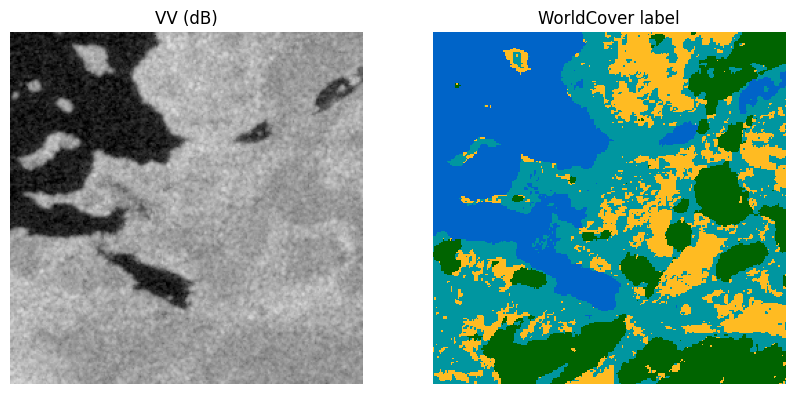

In [4]:
Xmm = np.load(f"{CACHE}/X.npy", mmap_mode="r"); Ymm = np.load(f"{CACHE}/Y.npy", mmap_mode="r")
r = idx[(idx.version == "v2") & (idx.split == "train")].sample(1, random_state=0).index[0]
x, y = Xmm[r] / 100, Ymm[idx.pid[r]]
print("row", r, "| file", os.path.basename(idx.path[r]), "| month", idx.month[r] + 1,
      "| VV dB range", x[0].min().round(1), x[0].max().round(1), "| classes", np.unique(y))
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(x[0], cmap="gray", vmin=-25, vmax=0); ax[0].set_title("VV (dB)")
ax[1].imshow(np.ma.masked_equal(y, 255), cmap=ListedColormap(COLORS), vmin=0, vmax=NC - 1, interpolation="nearest")
ax[1].set_title("WorldCover label")
for a in ax: a.axis("off")
plt.show()

Cell K2.1: preprocessing and augmentation

In [5]:
NODATA = stats["nodata"]

def preprocess(x2, stats):
    """x2: (2,H,W) dB*100 [VV,VH] -> (3,H,W) normalized + nodata mask. IDENTICAL to training/app."""
    nod = (x2[0] == stats["nodata"]) | (x2[1] == stats["nodata"])
    vv = np.clip(x2[0] / stats["scale"], *stats["clip"]["VV"])
    vh = np.clip(x2[1] / stats["scale"], *stats["clip"]["VH"])
    img = np.stack([vv, vh, vv - vh]).astype(np.float32)
    mean = np.array(stats["mean"], np.float32)[:, None, None]
    std = np.array(stats["std"], np.float32)[:, None, None]
    img = (img - mean) / std
    img[:, nod] = 0.0
    return img, nod

AUG = {"p_gain": 0.5, "gain_db": 1.0, "p_speckle": 0.5, "looks": 30}

def radar_augment(x2, rng, aug=AUG):
    """Radiometric augmentation in the dB domain. Nodata pixels stay nodata."""
    nod = (x2[0] == NODATA) | (x2[1] == NODATA)
    x = x2.astype(np.float32) / 100.0                                   # dB*100 -> dB
    if rng.random() < aug["p_gain"]:
        x += rng.uniform(-aug["gain_db"], aug["gain_db"])                # same offset VV and VH
    if rng.random() < aug["p_speckle"]:
        g = rng.gamma(aug["looks"], 1.0 / aug["looks"], size=x.shape).astype(np.float32)
        x += 10.0 * np.log10(g)                                          # multiplicative noise = additive in dB
    out = x * 100.0
    out[:, nod] = NODATA
    return out

Cell K2.2: neighbour lookup and dataset

In [6]:
row_of = {(pf, m): r for r, pf, m in zip(idx.index, idx.pid_file, idx.month)}
idx["prev_row"] = [row_of.get((pf, m - 1), r) for r, pf, m in zip(idx.index, idx.pid_file, idx.month)]
idx["next_row"] = [row_of.get((pf, m + 1), r) for r, pf, m in zip(idx.index, idx.pid_file, idx.month)]
print("rows with own prev month:", (idx.prev_row != idx.index).mean().round(3),
      "| with own next month:", (idx.next_row != idx.index).mean().round(3))

class S1DatasetV2(Dataset):
    def __init__(self, df, stats, augment=False, temporal=False):
        self.rows, self.pids = df.index.to_numpy(), df.pid.to_numpy()
        self.prev, self.next = df.prev_row.to_numpy(), df.next_row.to_numpy()
        self.stats, self.augment, self.temporal = stats, augment, temporal
        self.X = self.Y = None

    def __len__(self):
        return len(self.rows)

    def _month(self, r, rng):
        x2 = np.asarray(self.X[r])
        if self.augment:
            x2 = radar_augment(x2, rng)
        return preprocess(x2, self.stats)

    def __getitem__(self, i):
        if self.X is None:                                   # open lazily inside each worker
            self.X = np.load(f"{CACHE}/X.npy", mmap_mode="r")
            self.Y = np.load(f"{CACHE}/Y.npy", mmap_mode="r")
        rng = np.random.default_rng(random.getrandbits(32))  # per-sample generator (worker-safe)
        img, nod = self._month(self.rows[i], rng)
        if self.temporal:
            prev, _ = self._month(self.prev[i], rng)
            nxt, _ = self._month(self.next[i], rng)
            img = np.concatenate([prev, img, nxt])           # (9, H, W)
        y = self.Y[self.pids[i]].astype(np.int64)
        y[nod] = 255                                         # centre-month gaps are ignored
        if self.augment:                                     # geometry: same for all channels and label
            k = random.randint(0, 3)
            img, y = np.rot90(img, k, (1, 2)), np.rot90(y, k)
            if random.random() < 0.5:
                img, y = img[:, :, ::-1], y[:, ::-1]
        return torch.from_numpy(img.copy()), torch.from_numpy(y.copy())

rows with own prev month: 0.914 | with own next month: 0.914


Cell K2.3: visual check of the augmentation and temporal stacking

gain shift (dB): -0.46 | speckle std (dB): 0.8


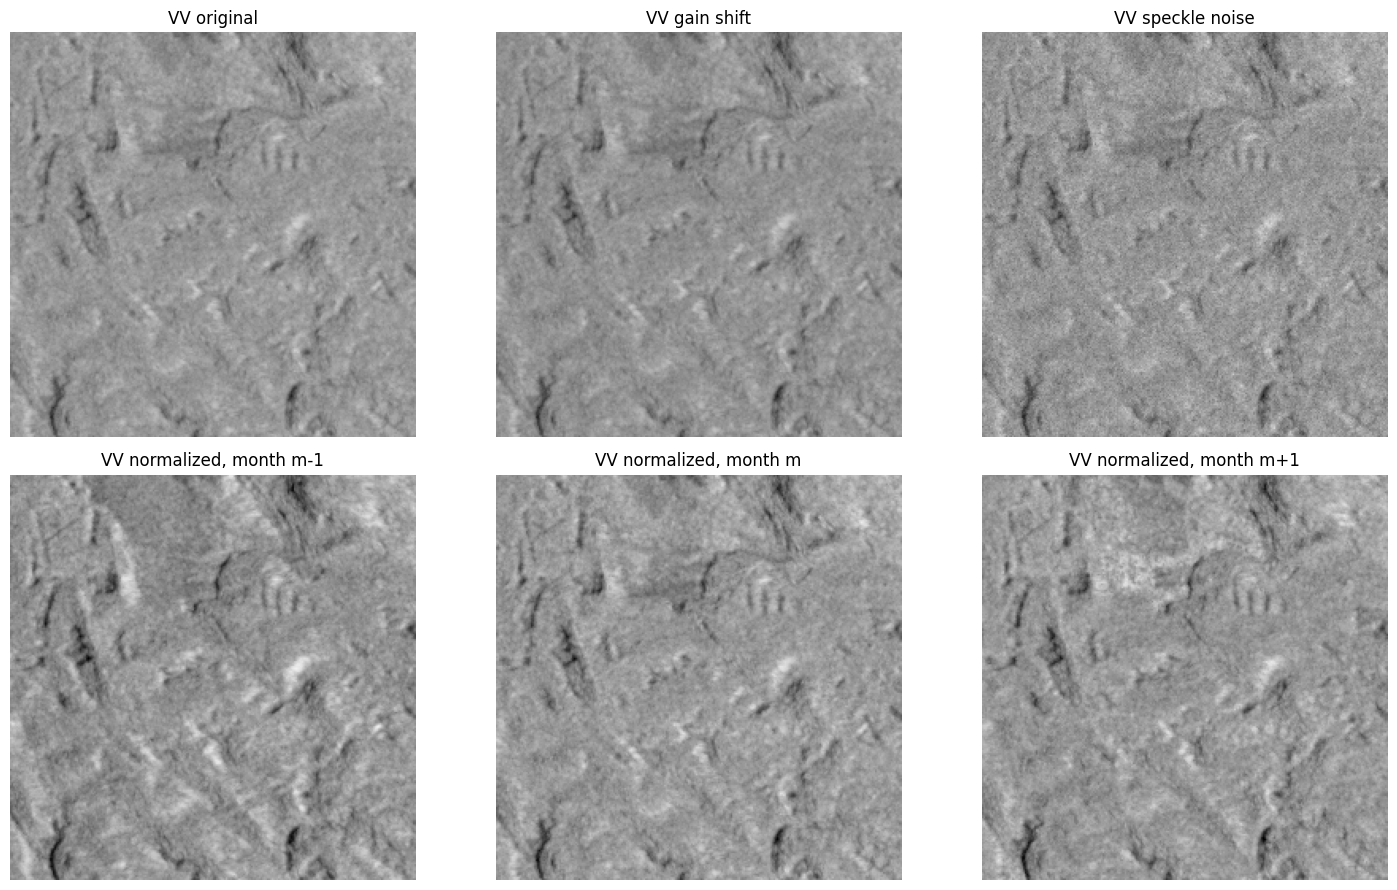

temporal tensor: (9, 256, 256) | label: (256, 256)


In [7]:
random.seed(1)
r = idx[(idx.split == "train") & (idx.prev_row != idx.index) & (idx.next_row != idx.index)].index[100]
x2 = np.asarray(np.load(f"{CACHE}/X.npy", mmap_mode="r")[r])
rng = np.random.default_rng(0)
gain_only = radar_augment(x2, rng, {"p_gain": 1, "gain_db": 1.0, "p_speckle": 0, "looks": 30})
speck_only = radar_augment(x2, rng, {"p_gain": 0, "gain_db": 1.0, "p_speckle": 1, "looks": 30})
valid = x2[0] != NODATA
print("gain shift (dB):", round(float((gain_only[0] - x2[0])[valid].mean() / 100), 2),
      "| speckle std (dB):", round(float((speck_only[0] - x2[0])[valid].std() / 100), 2))

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, (img, t) in zip(ax[0], [(x2, "original"), (gain_only, "gain shift"), (speck_only, "speckle noise")]):
    a.imshow(img[0] / 100, cmap="gray", vmin=-25, vmax=0); a.set_title(f"VV {t}")
dst = S1DatasetV2(idx.loc[[r]], stats, augment=False, temporal=True)
xt, yt = dst[0]
for a, c, t in zip(ax[1], [0, 3, 6], ["month m-1", "month m", "month m+1"]):
    a.imshow(xt[c], cmap="gray", vmin=-2, vmax=2); a.set_title(f"VV normalized, {t}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
print("temporal tensor:", tuple(xt.shape), "| label:", tuple(yt.shape))

Cell K2.4: loader speed for both variants

In [8]:
def make_ds(split, augment, temporal):
    return S1DatasetV2(idx[idx.split == split], stats, augment=augment, temporal=temporal)

for temporal in (False, True):
    ds_tr = make_ds("train", True, temporal)
    dl_tr = DataLoader(ds_tr, batch_size=16, shuffle=True, num_workers=4, pin_memory=True,
                       generator=torch.Generator().manual_seed(0))
    t0 = time.time()
    for k, (xb, yb) in enumerate(dl_tr):
        if k == 30: break
    sec = (time.time() - t0) / 30
    print(f"temporal={temporal}: x {tuple(xb.shape)} | {sec:.2f}s/batch -> ~{sec * len(dl_tr) / 60:.1f} min/epoch data time")

temporal=False: x (16, 3, 256, 256) | 0.06s/batch -> ~2.1 min/epoch data time
temporal=True: x (16, 9, 256, 256) | 0.13s/batch -> ~4.7 min/epoch data time


Cell K3.1: protocol, models, loss, metrics

In [9]:
CFG4 = {"epochs": 20, "lr": 3e-4, "weight_decay": 1e-2, "batch_size": 16, "seeds": [42, 43, 44],
        "loss": "weighted CE + Dice", "aug": AUG, "norm_stats": "norm_stats_v2.json",
        "data": "index_v2.csv (v1+v2)", "selection": "best val mIoU per run", "test_set": "untouched"}

RUN_MODEL = "deeplabv3p_r34_t3"   # per Kaggle job: "deeplabv3p_r34" | "segformer_b2" | "deeplabv3p_r34_t3"
SMOKE = False                   # True = quick test; set to False before "Save & Run All"
BS = CFG4["batch_size"]

def build_model(name):
    in_ch = 9 if name.endswith("_t3") else 3
    if name.startswith("deeplabv3p_r34"):
        return smp.DeepLabV3Plus("resnet34", encoder_weights="imagenet", in_channels=in_ch, classes=NC)
    if name == "segformer_b2":
        return smp.Segformer("mit_b2", encoder_weights="imagenet", in_channels=in_ch, classes=NC)
    raise ValueError(name)

w = torch.tensor(stats["class_weights"], dtype=torch.float32, device=DEVICE)
ce = nn.CrossEntropyLoss(weight=w, ignore_index=255)
dice = smp.losses.DiceLoss(mode="multiclass", ignore_index=255)
def loss_fn(logits, y):
    return ce(logits, y) + dice(logits, y)

def metrics_np(cm):
    cm = cm.astype(float); tp = np.diag(cm); ref, pred = cm.sum(1), cm.sum(0)
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.where(pred > 0, tp / pred, np.nan); rec = np.where(ref > 0, tp / ref, np.nan)
        f1 = 2 * prec * rec / (prec + rec); iou = np.where(ref > 0, tp / (ref + pred - tp), np.nan)
    return {"mIoU": np.nanmean(iou), "pixel_acc": tp.sum() / cm.sum(), "macro_F1": np.nanmean(f1), "IoU": iou}

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Cell K3.2: one epoch

In [10]:
def run_epoch(model, loader, train, opt=None, scaler=None, max_batches=None):
    model.train(train)
    cm = torch.zeros(NC, NC, dtype=torch.long, device=DEVICE); tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for b, (xb, yb) in enumerate(tqdm(loader, leave=False)):
            if max_batches and b >= max_batches:
                break
            xb = xb.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
            yb = yb.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(xb)
            loss = loss_fn(out.float(), yb)
            if train:
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * xb.size(0); n += xb.size(0)
            pred, m = out.detach().argmax(1), yb != 255
            cm += torch.bincount(yb[m] * NC + pred[m], minlength=NC * NC).reshape(NC, NC)
    res = metrics_np(cm.cpu().numpy()); res["loss"] = tot / max(n, 1)
    return res

Cell K3.3: train one model with one seed, and save everything

In [11]:
def train_one(name, seed):
    temporal = name.endswith("_t3")
    out = f"{WORK}/runs/{name}_s{seed}"; os.makedirs(out, exist_ok=True)
    epochs = 1 if SMOKE else CFG4["epochs"]; maxb = 50 if SMOKE else None
    set_seed(seed)
    ds_tr, ds_va = make_ds("train", True, temporal), make_ds("val", False, temporal)
    dl_tr = DataLoader(ds_tr, batch_size=BS, shuffle=True, num_workers=4, pin_memory=True, drop_last=True,
                       persistent_workers=True, prefetch_factor=4, generator=torch.Generator().manual_seed(seed))
    dl_va = DataLoader(ds_va, batch_size=BS, shuffle=False, num_workers=4, pin_memory=True,
                       persistent_workers=True, prefetch_factor=4)
    model = build_model(name).to(DEVICE).to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG4["lr"], weight_decay=CFG4["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda")
    torch.cuda.reset_peak_memory_stats(); best, hist, t_start = -1.0, [], time.time()

    for ep in range(epochs):
        t0 = time.time()
        tr = run_epoch(model, dl_tr, True, opt, scaler, maxb)
        va = run_epoch(model, dl_va, False, max_batches=maxb)
        sched.step()
        hist.append({"model": name, "seed": seed, "epoch": ep + 1, "epoch_s": round(time.time() - t0),
                     "train_loss": tr["loss"], "val_loss": va["loss"], "train_mIoU": tr["mIoU"],
                     "val_mIoU": va["mIoU"], "val_acc": va["pixel_acc"],
                     **{f"IoU_{c}": float(v) for c, v in zip(CLASSES, va["IoU"])}})
        if va["mIoU"] > best:
            best = va["mIoU"]
            torch.save({"model": model.state_dict(), "name": name, "seed": seed, "epoch": ep + 1,
                        "val_mIoU": best, "cfg": CFG4, "stats": stats}, f"{out}/best.pth")
        pd.DataFrame(hist).to_csv(f"{out}/history.csv", index=False)
        print(f"{name} s{seed} ep {ep + 1:02d} | {hist[-1]['epoch_s']}s | train {tr['loss']:.3f}/{tr['mIoU']:.3f} "
              f"| val {va['loss']:.3f}/{va['mIoU']:.3f}" + ("  *best" if va["mIoU"] >= best else ""))

    # per-sample val confusion matrices of the BEST checkpoint (for the bootstrap in M4.4)
    model.load_state_dict(torch.load(f"{out}/best.pth", map_location=DEVICE, weights_only=False)["model"])
    model.eval(); cms = []
    with torch.no_grad():
        for b, (xb, yb) in enumerate(dl_va):
            if maxb and b >= maxb:
                break
            xb = xb.to(DEVICE, memory_format=torch.channels_last); yb = yb.to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16):
                pred = model(xb).argmax(1)
            for k in range(len(yb)):
                m = yb[k] != 255
                cms.append(torch.bincount(yb[k][m] * NC + pred[k][m], minlength=NC * NC).reshape(NC, NC).cpu().numpy())
    rows = ds_va.rows[:len(cms)]
    np.savez_compressed(f"{out}/val_cms.npz", rows=rows, pid_file=idx.pid_file.values[rows], cms=np.stack(cms))
    mf = metrics_np(np.stack(cms).sum(0))
    summary = {"model": name, "seed": seed, "best_epoch": int(pd.DataFrame(hist).val_mIoU.idxmax()) + 1,
               "val_mIoU": round(mf["mIoU"], 4), "pixel_acc": round(mf["pixel_acc"], 4),
               "macro_F1": round(mf["macro_F1"], 4), "train_min": round((time.time() - t_start) / 60, 1),
               "peak_mem_GB": round(torch.cuda.max_memory_allocated() / 1e9, 2),
               "params_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
               **{f"IoU_{c}": round(float(v), 4) for c, v in zip(CLASSES, mf["IoU"])}}
    json.dump(summary, open(f"{out}/summary.json", "w"), indent=2)
    del model, opt, dl_tr, dl_va; torch.cuda.empty_cache()
    return summary

Cell K3.4: runner

In [12]:
os.makedirs(f"{WORK}/runs", exist_ok=True)
json.dump({**CFG4, "run_model": RUN_MODEL, "smoke": SMOKE}, open(f"{WORK}/runs/cfg_{RUN_MODEL}.json", "w"), indent=2)
results = []
for seed in (CFG4["seeds"][:1] if SMOKE else CFG4["seeds"]):
    print(f"===== {RUN_MODEL} | seed {seed} | smoke={SMOKE} =====")
    results.append(train_one(RUN_MODEL, seed))
    pd.DataFrame(results).to_csv(f"{WORK}/runs/summary_{RUN_MODEL}.csv", index=False)
pd.DataFrame(results).T

===== deeplabv3p_r34_t3 | seed 42 | smoke=False =====


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  0%|          | 0/2093 [00:00<?, ?it/s]

  0%|          | 0/431 [00:00<?, ?it/s]

... (175 outputs left out)

  0%|          | 0/2093 [00:00<?, ?it/s]

  0%|          | 0/431 [00:00<?, ?it/s]

deeplabv3p_r34_t3 s44 ep 20 | 277s | train 0.759/0.666 | val 1.466/0.521  *best


,0,1,2
model,deeplabv3p_r34_t3,deeplabv3p_r34_t3,deeplabv3p_r34_t3
seed,42,43,44
best_epoch,14,18,20
val_mIoU,0.522,0.5253,0.5211
pixel_acc,0.6805,0.6865,0.6816
macro_F1,0.6719,0.6756,0.6721
train_min,96.3,88.2,94.1
peak_mem_GB,1.37,1.37,1.37
params_M,22.5,22.5,22.5
IoU_Tree,0.6249,0.6305,0.6242
